In [ ]:
# Imports for Dataset
import numpy as np
import pandas as pd
import nltk
import re
import string
import tensorflow as tf

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Visualization
import plotly.express as px
import matplotlib.pyplot as plt

# Transformers
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from tensorflow.keras.optimizers.legacy import Adam  

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
df = pd.read_csv("data/fake_or_real_news.csv")
df = df[["text", "label"]].copy()

mapping = {"FAKE": 0, "REAL": 1}
df["Label"] = df["label"].map(mapping)

df = df[["text", "Label"]]
print("Dataset size:", len(df))
df.head()

Dataset size: 6335


,text,Label
0,"Daniel Greenfield, a Shillman Journalism Fello...",0
1,Google Pinterest Digg Linkedin Reddit Stumbleu...,0
2,U.S. Secretary of State John F. Kerry said Mon...,1
3,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",0
4,It's primary day in New York and front-runners...,1


In [4]:
data = df.sample(1000, random_state=42).reset_index(drop=True)
data.head()

,text,Label
0,Will Trump pull a Brexit times ten? What would...,0
1,Clintons Are Under Multiple FBI Investigations...,0
2,Dispatches from Eric Zuesse This piece is cros...,0
3,Print \n[Ed. – Every now and then the facade c...,0
4,Nanny In Jail After Force Feeding Baby To Deat...,0


In [5]:
def clean_text_basic(text):
    text = re.sub(r"<.*?>", " ", text)               # remove HTML
    text = re.sub(r"http\S+|www.\S+", " ", text)     # remove URLs
    text = re.sub(r"\s+", " ", text).strip()         # normalize spaces
    return text.lower()

In [6]:
def normalize_noise(text):
    text = re.sub(r"([!?.,])\1+", r"\1", text)         # !!! → !
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)         # heyyy → heyy
    return text

In [7]:
def remove_boilerplate(text):
    patterns = [
        r"^\s*reuters\s*[-–:]", 
        r"^\s*associated press\s*[-–:]", 
        r"^\s*[A-Z]{2,}\s*[-–:]"
    ]
    for p in patterns:
        text = re.sub(p, "", text, flags=re.IGNORECASE)
    return text.strip()

In [8]:
def full_clean(text):
    text = clean_text_basic(text)
    text = normalize_noise(text)
    text = remove_boilerplate(text)
    return text

data["clean_text"] = data["text"].apply(full_clean)

In [9]:
label_map = {0: "Fake", 1: "Real"}
data["LabelText"] = data["Label"].map(label_map)

fig = px.histogram(
    data_frame=data,
    y="LabelText",
    color="LabelText",
    text_auto=True,
    title="Fake & Real Samples Distribution",
    color_discrete_map={"Fake":"#636EFA","Real":"#EF553B"}
)
fig.update_layout(showlegend=False)
fig.show()

In [10]:
X = data["clean_text"].to_numpy()
Y = data["Label"].to_numpy().astype("float32").reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.1,
    stratify=Y,
    random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train, y_train,
    test_size=0.1,
    stratify=y_train,
    random_state=42
)

In [11]:
bert_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    bert_name,
    do_lower_case=True
)

max_len = 256

In [12]:
X_train_enc = tokenizer(
    X_train.tolist(),
    padding=True,
    truncation=True,
    max_length=max_len,
    return_tensors="tf"
).input_ids

X_valid_enc = tokenizer(
    X_valid.tolist(),
    padding=True,
    truncation=True,
    max_length=max_len,
    return_tensors="tf"
).input_ids

X_test_enc = tokenizer(
    X_test.tolist(),
    padding=True,
    truncation=True,
    max_length=max_len,
    return_tensors="tf"
).input_ids

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
2025-11-28 11:43:41.612425: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2025-11-28 11:43:41.612800: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-11-28 11:43:41.614720: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-11-28 11:43:41.614997: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-11-28 11:43:41.615484: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [13]:
batch = 4

train_ds = tf.data.Dataset.from_tensor_slices((X_train_enc, y_train)).shuffle(800).batch(batch)
valid_ds = tf.data.Dataset.from_tensor_slices((X_valid_enc, y_valid)).batch(batch)
test_ds  = tf.data.Dataset.from_tensor_slices((X_test_enc, y_test)).batch(batch)

In [14]:
bert_model = TFAutoModelForSequenceClassification.from_pretrained(
    bert_name,
    num_labels=1,
    problem_type="single_label_classification",
    from_pt=True
)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFDistilBertForSequenceClassification: ['vocab_projector.weight', 'vocab_transform.bias', 'vocab_layer_norm.bias', 'vocab_layer_norm.weight', 'vocab_transform.weight', 'vocab_projector.bias']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTrain

In [15]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(data["Label"]),
    y=data["Label"]
)

class_weights = {0: class_weights[0], 1: class_weights[1]}
class_weights

{0: 1.0266940451745379, 1: 0.9746588693957114}

In [16]:
bert_model.compile(
    optimizer=Adam(learning_rate=2e-5),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
        tf.keras.metrics.Precision(name="Precision"),
        tf.keras.metrics.Recall(name="Recall"),
    ]
)

In [17]:
callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [18]:
history = bert_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=8,
    batch_size=batch,
    class_weight=class_weights,
    callbacks=[callback]
)

hist = pd.DataFrame(history.history)
hist

Epoch 1/8


2025-11-28 11:45:45.868406: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


203/203 [==============================] - 93s 403ms/step - loss: 0.3676 - Accuracy: 0.8099 - Precision: 0.9253 - Recall: 0.6851 - val_loss: 0.1939 - val_Accuracy: 0.9333 - val_Precision: 0.9167 - val_Recall: 0.9565
Epoch 2/8
203/203 [==============================] - 78s 384ms/step - loss: 0.0846 - Accuracy: 0.9753 - Precision: 0.9806 - Recall: 0.9712 - val_loss: 0.1870 - val_Accuracy: 0.9444 - val_Precision: 0.9020 - val_Recall: 1.0000
Epoch 3/8
203/203 [==============================] - 79s 387ms/step - loss: 0.0314 - Accuracy: 0.9926 - Precision: 0.9928 - Recall: 0.9928 - val_loss: 0.1203 - val_Accuracy: 0.9556 - val_Precision: 0.9200 - val_Recall: 1.0000
Epoch 4/8
203/203 [==============================] - 81s 394ms/step - loss: 0.0353 - Accuracy: 0.9901 - Precision: 0.9880 - Recall: 0.9928 - val_loss: 0.2391 - val_Accuracy: 0.9222 - val_Precision: 0.8679 - val_Recall: 1.0000
Epoch 5/8
203/203 [==============================] - 73s 361ms/step - loss: 0.0482 - Accuracy: 0.9864 - Pr

,loss,Accuracy,Precision,Recall,val_loss,val_Accuracy,val_Precision,val_Recall
0,0.367615,0.809877,0.925325,0.685096,0.193924,0.933333,0.916667,0.956522
1,0.084576,0.975309,0.980583,0.971154,0.187015,0.944444,0.901961,1.000000
2,0.031398,0.992593,0.992788,0.992788,0.120343,0.955556,0.920000,1.000000
3,0.035304,0.990123,0.988038,0.992788,0.239150,0.922222,0.867925,1.000000
4,0.048224,0.986420,0.992701,0.980769,0.197155,0.944444,0.901961,1.000000


In [19]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=2, cols=2, 
                    subplot_titles=("Loss", "Accuracy", "Precision", "Recall"))

fig.add_trace(go.Scatter(y=hist['loss'], name="Train Loss"), row=1, col=1)
fig.add_trace(go.Scatter(y=hist['val_loss'], name="Val Loss"), row=1, col=1)

fig.add_trace(go.Scatter(y=hist['Accuracy'], name="Train Acc"), row=1, col=2)
fig.add_trace(go.Scatter(y=hist['val_Accuracy'], name="Val Acc"), row=1, col=2)

fig.add_trace(go.Scatter(y=hist['Precision'], name="Train Prec"), row=2, col=1)
fig.add_trace(go.Scatter(y=hist['val_Precision'], name="Val Prec"), row=2, col=1)

fig.add_trace(go.Scatter(y=hist['Recall'], name="Train Recall"), row=2, col=2)
fig.add_trace(go.Scatter(y=hist['val_Recall'], name="Val Recall"), row=2, col=2)

fig.update_layout(height=800, title="Training History")
fig.show()

In [20]:
test_loss, test_acc, test_prec, test_rec = bert_model.evaluate(test_ds, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)
print("Test Precision:", test_prec)
print("Test Recall:", test_rec)

Test Loss: 0.13010644912719727
Test Accuracy: 0.9399999976158142
Test Precision: 0.9245283007621765
Test Recall: 0.9607843160629272


25/25 [==============================] - 9s 173ms/step


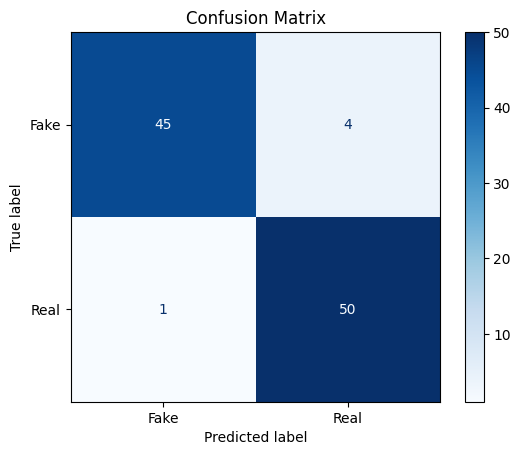

In [21]:
y_pred = (bert_model.predict(test_ds).logits > 0).astype(int)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fake","Real"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

In [22]:
print(classification_report(y_test, y_pred, target_names=["Fake","Real"]))

              precision    recall  f1-score   support

        Fake       0.98      0.92      0.95        49
        Real       0.93      0.98      0.95        51

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100



In [23]:
def predict_text(text):
    ids = tokenizer(text, return_tensors="tf", padding="max_length", truncation=True, max_length=max_len).input_ids
    pred = bert_model.predict(ids, verbose=0).logits
    return int(pred > 0)

CLASS_NAMES = ["Fake", "Real"]

for _ in range(5):
    i = np.random.randint(len(X_test))
    text = X_test[i]
    true = int(y_test[i])
    pred = predict_text(text)

    print(f"\nTEXT:\n{text[:600]}...")
    print(f"TRUE: {CLASS_NAMES[true]}  |  PRED: {CLASS_NAMES[pred]}")
    print("-"*90)


TEXT:
by wmw_admin on october 29, 2016 morgan chalfant — washington free beacon oct 28, 2016 u.s. and russian military jets reportedly had a close encounter in syrian airspace several days ago. afp, citing u.s. officials, reported friday morning that a russian fighter jet flew dangerously close to a u.s. jet in airspace over eastern syria on oct. 17, nearly two weeks prior. a russian jet escorting a larger spy aircraft flew into the vicinity of the u.s. warplane, moving to “inside half a mile” from the american plane, according to air force lieutenant general jeff harrigian. #breaking russian, us je...
TRUE: Fake  |  PRED: Fake
------------------------------------------------------------------------------------------

TEXT:
get short url 0 5 0 0 a strong energy sector will serve as an economic driver for the uk's economy, britain's former minister for energy and climate change told sputnik. moscow (sputnik) — the united kingdom is interested in a strong energy sector as an economic dr